# 02 · Hotspot mapping

**Question:** where is personal-safety crime concentrated in Leeds, and does that match where the nightlife venues are?

| Step | What happens |
|---|---|
| 1 | Map the raw crime and venue points |
| 2 | Estimate crime density with Kernel Density Estimation (KDE) |
| 3 | Overlay the venues on the crime density surface |
| 4 | Measure the overlap between the crime hotspot and the venue hotspot |
| 5 | Save an interactive map |

All distance-based work uses British National Grid (EPSG:27700), which is measured in metres.

In [1]:
import sys
from pathlib import Path

# Make the project's `src` package importable from inside notebooks/
sys.path.insert(0, str(Path.cwd().resolve().parent))

import folium
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from folium.plugins import HeatMap, MarkerCluster
from matplotlib.lines import Line2D

from src import config, geo, plotting

In [2]:
crimes = pd.read_csv(config.CRIMES_CLEAN)
venues = pd.read_csv(config.VENUES_CLEAN)
lsoas = geo.load_leeds_lsoas()

crime_pts = geo.to_points(crimes, lon="Longitude", lat="Latitude")
venue_pts = geo.to_points(venues, lon="longitude", lat="latitude")

inside = gpd.sjoin(venue_pts, lsoas[["geometry"]], predicate="within")
print(f"{len(crime_pts):,} incidents and {len(venue_pts):,} venues ({len(inside):,} inside the Leeds boundary)")

Leeds LSOAs: 488 (of 35,672 in England and Wales)


111,549 incidents and 715 venues (714 inside the Leeds boundary)


## Step 1 · Raw points

Plotting every incident shows the overall pattern, but the city centre has so many points that they overlap into a solid mass. That's why Step 2 smooths them into a density surface.

Saved results\figures\crime_points.png


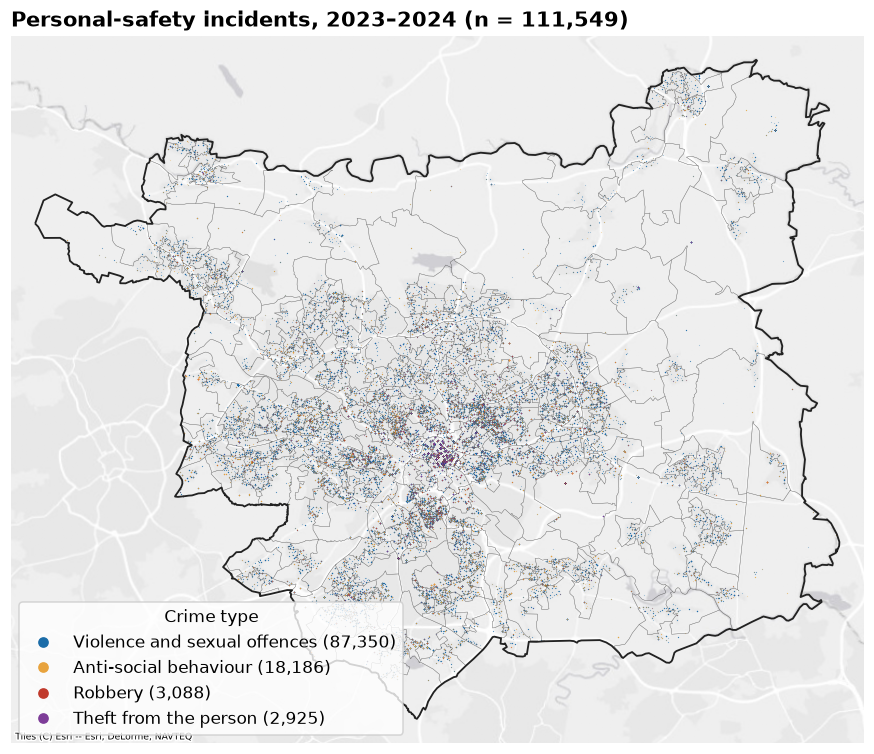

In [3]:
fig, ax = plotting.map_axes(lsoas, f"Personal-safety incidents, 2023–2024 (n = {len(crime_pts):,})")
handles = []
for crime_type in config.SAFETY_CRIMES:  # largest category first, so smaller ones draw on top
    subset = crime_pts[crime_pts["Crime type"] == crime_type]
    colour = config.CRIME_COLOURS[crime_type]
    ax.scatter(subset.geometry.x, subset.geometry.y, s=0.6, color=colour, alpha=0.35, linewidths=0, zorder=2)
    handles.append(Line2D([], [], marker="o", ls="", color=colour, label=f"{crime_type} ({len(subset):,})"))
plotting.draw_lsoas(ax, lsoas)
ax.legend(handles=handles, loc="lower left", title="Crime type", frameon=True)
plotting.save(fig, "crime_points");

Saved results\figures\venue_points.png


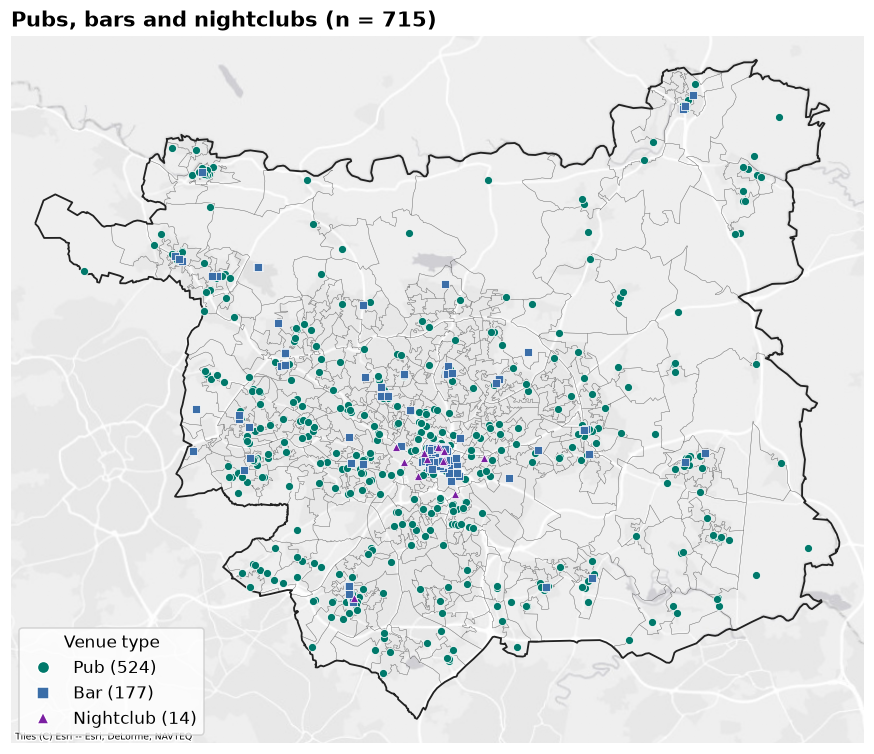

In [4]:
fig, ax = plotting.map_axes(lsoas, f"Pubs, bars and nightclubs (n = {len(venue_pts):,})")
plotting.draw_lsoas(ax, lsoas)
handles = []
for venue_type, (marker, colour) in config.VENUE_STYLE.items():
    subset = venue_pts[venue_pts["amenity_type"] == venue_type]
    ax.scatter(subset.geometry.x, subset.geometry.y, marker=marker, s=28, color=colour,
               edgecolor="white", linewidth=0.5, zorder=5)
    handles.append(Line2D([], [], marker=marker, ls="", color=colour, markeredgecolor="white",
                          markersize=8, label=f"{venue_type.title()} ({len(subset)})"))
ax.legend(handles=handles, loc="lower left", title="Venue type", frameon=True)
plotting.save(fig, "venue_points");

## Step 2 · Crime density (KDE)

Kernel Density Estimation places a smooth Gaussian "bump" over every incident and adds them up, turning overlapping points into a continuous surface. The result is scaled to **estimated incidents per km²**, so the colour scale has real units.

* **Bandwidth: 300 m**, roughly a few city blocks. It's small enough to separate the city centre from nearby suburbs, but large enough to smooth over the police's location anonymisation, which moves each incident to a nearby map point.
* **Grid: 100 m cells**, evaluated only inside the Leeds boundary.
* **Logarithmic colour scale (10 to 10,000 per km²)**: density varies a thousandfold between rural areas and the city centre, and a linear scale would hide everything but the peak.

In [5]:
crime_kde = geo.density_surface(crime_pts, lsoas)
venue_kde = geo.density_surface(venue_pts, lsoas)

values = crime_kde.inside()
print(f"Crime density inside Leeds: median {np.median(values):,.0f}, "
      f"97.5th percentile {np.percentile(values, 97.5):,.0f}, max {values.max():,.0f} incidents per km²")

Crime density inside Leeds: median 31, 97.5th percentile 1,200, max 9,564 incidents per km²


Saved results\figures\crime_kde.png


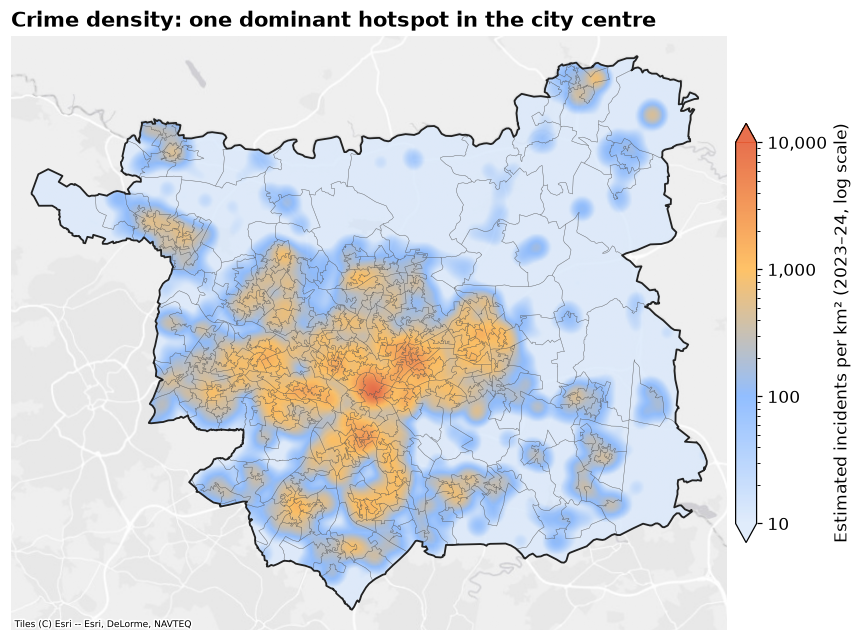

In [6]:
def draw_kde(ax, surface, alpha=0.85):
    return ax.imshow(surface.values, extent=surface.extent, origin="lower", cmap=plotting.KDE_CMAP,
                     norm=plotting.kde_norm(), alpha=alpha, zorder=2, interpolation="bilinear")

def add_density_colorbar(fig, image, ax, **kwargs):
    bar = fig.colorbar(image, ax=ax, extend="both", **kwargs)
    bar.set_ticks([10, 100, 1_000, 10_000], labels=["10", "100", "1,000", "10,000"])
    bar.set_label("Estimated incidents per km² (2023–24, log scale)")
    return bar

fig, ax = plotting.map_axes(lsoas, "Crime density: one dominant hotspot in the city centre")
image = draw_kde(ax, crime_kde)
plotting.draw_lsoas(ax, lsoas)
add_density_colorbar(fig, image, ax, shrink=0.55, pad=0.01)
plotting.save(fig, "crime_kde");

## Step 3 · Overlay the venues

The left panel shows the whole district. The right panel zooms in on a 5 km square around the point of highest crime density.

Saved results\figures\kde_venue_overlay.png


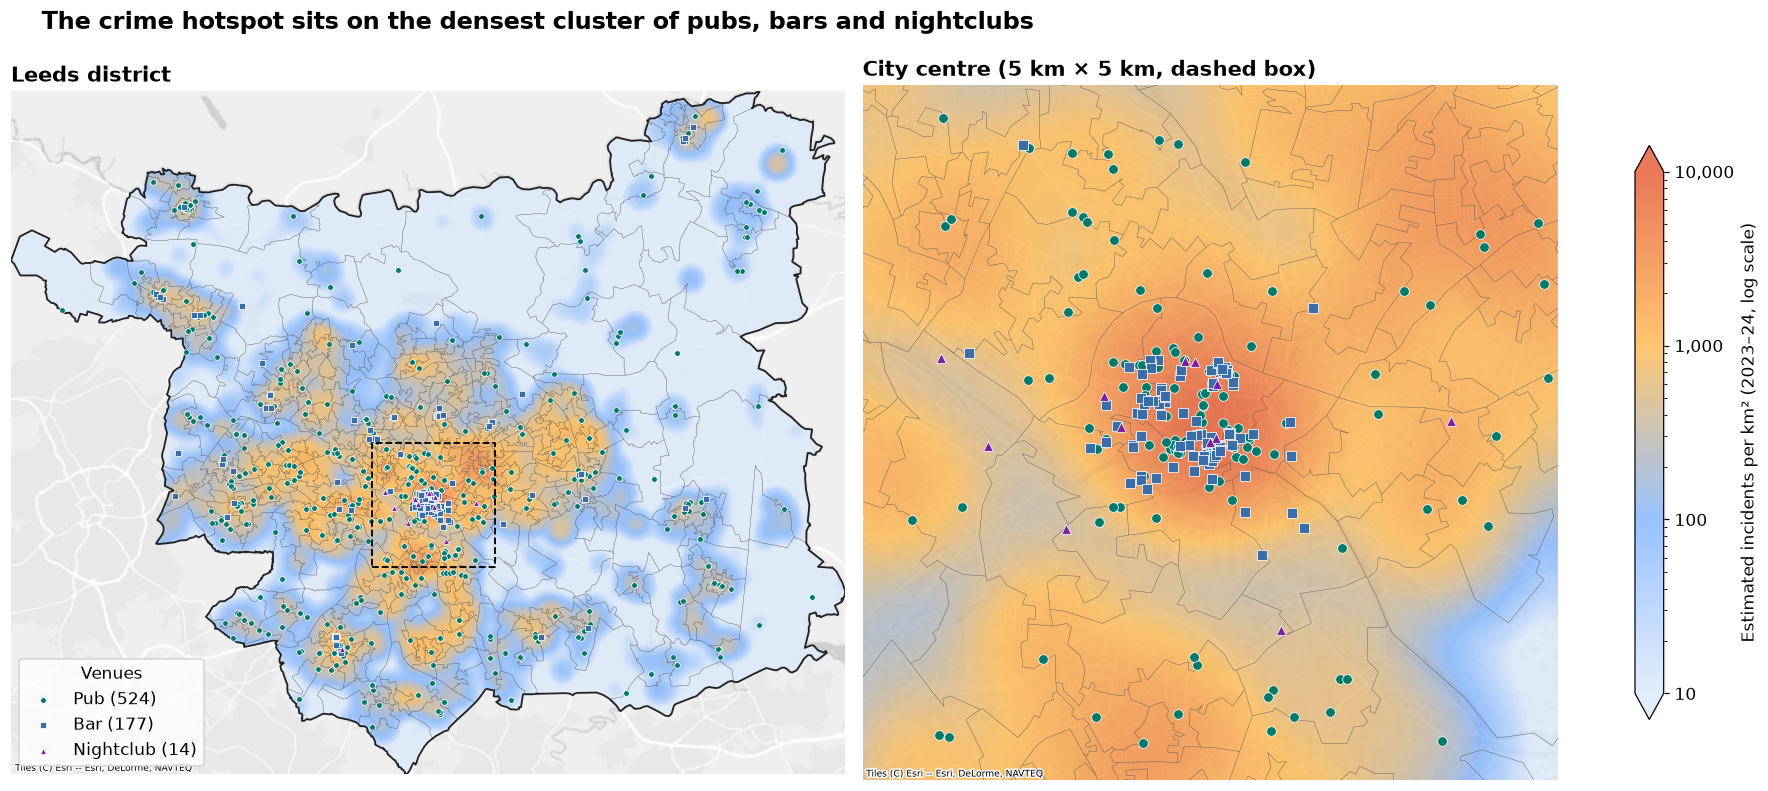

In [7]:
row, col = np.unravel_index(np.nanargmax(crime_kde.values), crime_kde.values.shape)
peak_x = crime_kde.extent[0] + (col + 0.5) * crime_kde.cell_size
peak_y = crime_kde.extent[2] + (row + 0.5) * crime_kde.cell_size
half = 2500  # metres either side of the peak

fig, axes = plt.subplots(1, 2, figsize=(16, 7.4), layout="constrained",
                         gridspec_kw={"width_ratios": [1.2, 1]})
for ax, zoomed in zip(axes, [False, True]):
    xmin, ymin, xmax, ymax = lsoas.total_bounds
    ax.set_xlim(*(peak_x - half, peak_x + half) if zoomed else (xmin, xmax))
    ax.set_ylim(*(peak_y - half, peak_y + half) if zoomed else (ymin, ymax))
    ax.set_axis_off()
    plotting.add_basemap(ax)
    image = draw_kde(ax, crime_kde, alpha=0.8)
    plotting.draw_lsoas(ax, lsoas)
    for venue_type, (marker, colour) in config.VENUE_STYLE.items():
        subset = venue_pts[venue_pts["amenity_type"] == venue_type]
        ax.scatter(subset.geometry.x, subset.geometry.y, marker=marker, s=40 if zoomed else 14,
                   color=colour, edgecolor="white", linewidth=0.5, zorder=5,
                   label=f"{venue_type.title()} ({len(subset)})")

axes[0].plot([peak_x - half, peak_x + half, peak_x + half, peak_x - half, peak_x - half],
             [peak_y - half, peak_y - half, peak_y + half, peak_y + half, peak_y - half],
             color="black", linewidth=1.2, linestyle="--", zorder=6)
axes[0].set_title("Leeds district")
axes[1].set_title("City centre (5 km × 5 km, dashed box)")
axes[0].legend(loc="lower left", title="Venues", frameon=True)
add_density_colorbar(fig, image, axes, shrink=0.75)
fig.suptitle("The crime hotspot sits on the densest cluster of pubs, bars and nightclubs",
             x=0.02, ha="left", fontsize=16, fontweight="bold")
plotting.save(fig, "kde_venue_overlay");

## Step 4 · Measure the overlap

Step 3 shows the overlap visually. This step puts a number on it.

1. Define the **crime hotspot area** as the densest 10% of grid cells for crime, and the **venue hotspot area** the same way for venues.
2. Count how many crime hotspot cells are also venue hotspot cells. If crime and venues were unrelated, about **10%** would overlap by chance.
3. Count what share of all incidents and all venues fall inside the crime hotspot area.

In [8]:
overlap = geo.hotspot_overlap(crime_kde, venue_kde)
crime_top = geo.top_area_mask(crime_kde)

summary = pd.DataFrame([
    {"Measure": "Crime hotspot cells that are also venue hotspot cells (%)", "Value": overlap["overlap_pct"]},
    {"Measure": "Overlap vs. chance (10%)", "Value": f"{overlap['times_chance']}×"},
    {"Measure": "Incidents inside the crime hotspot area (%)", "Value": geo.share_of_points_in_area(crime_pts, crime_kde, crime_top)},
    {"Measure": "Venues inside the crime hotspot area (%)", "Value": geo.share_of_points_in_area(venue_pts, crime_kde, crime_top)},
])
summary.to_csv(config.TABLES_DIR / "kde_overlap.csv", index=False)
summary

,Measure,Value
0,Crime hotspot cells that are also venue hotspo...,39.5
1,Overlap vs. chance (10%),3.9×
2,Incidents inside the crime hotspot area (%),64.8
3,Venues inside the crime hotspot area (%),52.4


**Reading the table:** the densest 10% of Leeds holds a large share of all incidents, and a much larger share of venues than its size would suggest. The crime and venue hotspots overlap far more than chance would produce. That's a strong spatial association, but it doesn't prove that venues *cause* the crime; see the README limitations.

## Step 5 · Interactive map

A zoomable version for exploring individual areas: crime heat map, clustered venue markers and LSOA boundaries.

In [9]:
config.MAPS_DIR.mkdir(parents=True, exist_ok=True)
lsoas_web = lsoas.assign(geometry=lsoas.geometry.simplify(15)).to_crs(config.CRS_WGS84)
centre = lsoas.union_all().centroid
centre_wgs = gpd.GeoSeries([centre], crs=config.CRS_BNG).to_crs(config.CRS_WGS84).iloc[0]

m = folium.Map(location=[centre_wgs.y, centre_wgs.x], zoom_start=11, tiles="OpenStreetMap")
folium.GeoJson(lsoas_web, name="LSOA boundaries",
               style_function=lambda _: {"fillOpacity": 0, "color": "#555", "weight": 0.5},
               tooltip=folium.GeoJsonTooltip(fields=["LSOA21NM"], aliases=["LSOA"])).add_to(m)
HeatMap(crimes[["Latitude", "Longitude"]].values.tolist(), name="Crime density",
        radius=8, blur=12, min_opacity=0.3).add_to(m)

cluster = MarkerCluster(name="Venues").add_to(m)
for _, v in venues.iterrows():
    colour = config.VENUE_STYLE.get(v["amenity_type"], ("o", "#666"))[1]
    folium.CircleMarker([v["latitude"], v["longitude"]], radius=5, color="white", weight=1,
                        fill=True, fill_color=colour, fill_opacity=0.95,
                        tooltip=f"{v['name']} ({v['amenity_type']})").add_to(cluster)

folium.LayerControl(collapsed=False).add_to(m)
out = config.MAPS_DIR / "leeds_crime_venues_map.html"
m.save(out)
print("Saved", out.relative_to(config.PROJECT_ROOT))

Saved results\maps\leeds_crime_venues_map.html


Next: [03_hotspot_significance.ipynb](03_hotspot_significance.ipynb) checks whether the hotspot is statistically significant.